# Linear regression

Giả sử đang tìm mua chung cư. Có một căn 70 m², cách trung tâm 8 km, người ta rao 4,2 tỷ, kèm câu quen thuộc: “Giá này rất hời.” Hời thật không? Nếu trong tay có giá của 200 căn đã bán quanh đó, nên làm gì? Thông thường ta sẽ ước lượng theo trực giác: căn rộng hơn thì đắt hơn, xa trung tâm thì rẻ đi. Linear regression (hồi quy tuyến tính) là trực giác ấy được viết thành toán học. Đây là mô hình đơn giản nhất của học máy, nhưng cần học kỹ, vì gần như mọi mô hình về sau, từ logistic regression đến mạng neural, đều dùng lại các ý của bài này.

> **Mục tiêu sau bài này**
>
> - Hiểu mô hình tuyến tính đang giả định điều gì, và đọc được ý nghĩa của từng hệ số.
> - Biết hai cách tìm nghiệm, nghiệm đóng và gradient descent, và lúc nào dùng cách nào.
> - Giải thích được vì sao learning rate lớn thì loss nổ tung, và vì sao phải chuẩn hóa đặc trưng. Phần học sâu dùng lại điều này rất nhiều.
> - Dùng scikit-learn đúng quy trình, tự cài lại bằng NumPy khi cần, và tránh được những bẫy hay gặp.

## Dữ liệu và mô hình

Ta bắt đầu từ dữ liệu. Để không phải tải dữ liệu từ Internet, ta tự sinh 200 căn hộ theo một công thức định giá có sẵn: giá $= 0.05 \cdot \text{diện tích} - 0.15 \cdot \text{khoảng cách} + 1$ (tỷ đồng), cộng thêm một chút nhiễu. Như vậy ta biết trước đáp án và có thể kiểm tra mô hình học đúng hay sai. Code trong bài chạy nối tiếp như các ô của notebook; notebook có thể tải ở mục lục bên phải, mở trên Colab hoặc Kaggle và chạy theo từng bước.

In [ ]:
import numpy as np

rng = np.random.default_rng(0)
n = 200
area = rng.uniform(30, 120, n)                                # diện tích, m²
dist = rng.uniform(1, 15, n)                                  # khoảng cách đến trung tâm, km
y = 0.05 * area - 0.15 * dist + 1.0 + rng.normal(0, 0.3, n)   # giá, tỷ đồng

X = np.column_stack([area, dist])
print(X.shape, y.shape)
print(X[:3].round(1))
print(y[:3].round(2))

(200, 2) (200,)
[[87.3  5.5]
 [54.3  3.6]
 [33.7 10.4]]
[4.48 3.   1.28]


Ý tưởng của mô hình: mỗi đặc trưng đóng góp vào giá một lượng tỉ lệ với nó, rồi cộng tất cả lại. Viết thành công thức, với mỗi mẫu có $d$ đặc trưng $\mathbf{x} = (x_1, \dots, x_d)$ (ở ví dụ này $d = 2$: diện tích và khoảng cách), mô hình dự đoán

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_d x_d + b = \mathbf{w}^\top \mathbf{x} + b.$$

$\mathbf{w}$ là vector trọng số (weights), $b$ là hệ số tự do (bias, intercept). $b$ dời kết quả lên hay xuống kể cả khi mọi đặc trưng bằng 0, và cũng được học như trọng số; mô hình có $d$ trọng số cộng 1 bias, tức $d+1$ tham số. Một nơ-ron ở chương 3 tính đúng tổng có trọng số này: đầu vào 2 và 3, trọng số 1 và 2, bias 0 cho $2\cdot1+3\cdot2=8$. Đọc $w_j$ như sau: nếu $x_j$ tăng thêm một đơn vị **trong khi mọi đặc trưng khác đứng yên**, thì dự đoán tăng thêm $w_j$. Điều kiện “mọi đặc trưng khác đứng yên” rất quan trọng; phần đọc hệ số ở cuối bài sẽ quay lại điểm này. Còn khi tính cho cả $n$ mẫu một lúc, ta xếp các mẫu thành các hàng của ma trận $X$, ở đây là 200 hàng, 2 cột:

$$\hat{\mathbf{y}} = X\mathbf{w} + b.$$

$X\mathbf{w}$ là một vector, còn $b$ là một số: phép cộng ở đây là cộng $b$ vào từng phần tử, vì căn nào cũng được cộng cùng một khoản $b$. NumPy cũng tự làm đúng như vậy.

Trước khi viết code, nên ghi rõ shape của từng đại lượng. Trong C++ kích thước mảng được khai báo tường minh; NumPy thì không yêu cầu, nên người viết phải tự kiểm soát.

| Ký hiệu | Ý nghĩa | Shape |
|---|---|---|
| $X$ | Ma trận đặc trưng, mỗi hàng một mẫu | `(n, d)` |
| $\mathbf{w}$ | Trọng số | `(d,)` |
| $b$ | Bias | số thực |
| $\hat{\mathbf{y}} = X\mathbf{w} + b$ | Dự đoán | `(n,)` |
| $\mathbf{y}$ | Giá trị thật | `(n,)` |

Cách viết `(d,)` là NumPy đang nói “mảng một chiều có $d$ phần tử”. Cả khóa này ta thống nhất: vector là mảng một chiều `(n,)`, không dùng mảng cột `(n, 1)`. Lý do được giải thích ở phần bẫy cài đặt.

**Hỏi nhanh.** `X` có shape `(200, 2)`, `w` có shape `(2,)`. `X @ w + b` có shape gì?

- A. `(200,)`
- B. `(2,)`
- C. `(200, 2)`
- D. `(200, 1)`

<details><summary>Đáp án</summary>

A. `(200,)`

Mỗi hàng của `X` nhân vô hướng với `w` cho ra một số, nên 200 hàng cho 200 số. Chọn `(200, 1)` là nhầm theo thói quen viết vector cột trong sách toán. NumPy không tự sinh thêm chiều thứ hai ấy.

</details>

## Hàm mất mát

Muốn chọn $\mathbf{w}$ và $b$ “tốt nhất” thì trước hết phải nói rõ thế nào là tốt. Với mỗi căn, ta đo độ lệch giữa dự đoán và giá thật, gọi là phần dư (residual) $r_i = \hat y_i - y_i$. Rồi lấy trung bình bình phương các phần dư, gọi là sai số bình phương trung bình (mean squared error):

$$J(\mathbf{w}, b) = \frac{1}{n}\sum_{i=1}^{n}\left(\mathbf{w}^\top \mathbf{x}_i + b - y_i\right)^2.$$

Vì sao dùng bình phương mà không dùng trị tuyệt đối? Trị tuyệt đối cũng dùng được, và thường được chọn khi dữ liệu có nhiều điểm bất thường. Nhưng bình phương có ba ưu điểm. Nó trơn, có đạo hàm tại mọi điểm, nên có nghiệm đóng và tối ưu bằng gradient thuận lợi. Nó phạt lỗi lớn nặng hơn hẳn lỗi nhỏ: sai 10 bị phạt 100, gấp bốn lần sai 5. Và về mặt thống kê, nếu nhiễu có phân phối chuẩn thì cực tiểu MSE chính là ước lượng hợp lý cực đại (maximum likelihood); ý này sẽ gặp lại khi học xác suất, giờ chỉ cần biết đây không phải lựa chọn tùy tiện. Cái giá phải trả là MSE rất nhạy với điểm ngoại lai (outlier): một căn bị nhập nhầm giá có thể kéo lệch cả đường thẳng.

Loss là con số đo dự đoán đang lệch đáp án bao nhiêu; học là làm loss giảm. Hồi quy đo độ lệch giữa hai con số, như MSE; phân loại đo xác suất mô hình dành cho nhãn đúng, như cross-entropy ở bài 2.3. Một loss dùng được phải nhỏ nhất khi đoán đúng: trung bình của $(\hat y-y)^3$ giữ dấu, nên cứ hạ dự đoán xuống là loss giảm mãi, không có cực tiểu. Nếu nhiễu của mẫu $i$ có phương sai riêng $\sigma_i^2$, hợp lý cực đại thành bình phương tối thiểu có trọng số $\sum_i (y_i-\hat y_i)^2/\sigma_i^2$; nhiễu kiểu Laplace thì thành tổng trị tuyệt đối.



Viết hai hàm nhỏ, rồi thử mô hình đơn giản nhất có thể: đoán mọi căn đều có giá bằng giá trung bình.

In [ ]:
def predict(X, w, b):
    return X @ w + b

def mse(y_hat, y):
    return np.mean((y_hat - y) ** 2)

print(mse(np.full(n, y.mean()), y))   # đoán mọi căn đều có giá trung bình
print(y.var())

2.34147721596206
2.34147721596206


Hai con số bằng nhau, và đây không phải trùng hợp: phương sai được định nghĩa đúng là trung bình bình phương độ lệch so với giá trị trung bình, tức là MSE của mô hình đoán trung bình. Con số này là mốc so sánh: mô hình nào có MSE không thấp hơn mốc này thì chưa học được gì. Người ta đo mức thắng bằng hệ số xác định $R^2 = 1 - \text{MSE}/\operatorname{Var}(y)$: bằng 0 là ngang với đoán theo trung bình, bằng 1 là đoán trúng hết.

**Hỏi nhanh.** Đổi đơn vị giá từ tỷ đồng sang triệu đồng, tức nhân mọi $y$ với 1000. MSE thay đổi thế nào?

- A. Không đổi
- B. Tăng 1000 lần
- C. Tăng $10^6$ lần
- D. Giảm 1000 lần

<details><summary>Đáp án</summary>

C. Tăng $10^6$ lần

Đơn vị của MSE là bình phương đơn vị của $y$, ở đây là tỷ đồng bình phương. Đổi sang triệu thì mỗi phần dư nhân 1000, bình phương lên thành $10^6$. Vì thế khi báo cáo, người ta hay dùng $\text{RMSE} = \sqrt{\text{MSE}}$, cùng đơn vị với giá, hoặc dùng $R^2$, không phụ thuộc đơn vị.

</details>

## Nghiệm đóng

Với MSE, bài toán tìm $\mathbf{w}$ và $b$ có lời giải chính xác bằng công thức, gọi là nghiệm đóng. Trước tiên là một kỹ thuật sẽ dùng lại nhiều lần: thêm vào $X$ một cột toàn số 1. Gọi ma trận mới là $\tilde X = [X \;\; \mathbf{1}]$ (shape `(n, d+1)`) và gộp $\boldsymbol\theta = (\mathbf{w}, b)$; khi đó $\hat{\mathbf{y}} = \tilde X \boldsymbol\theta$, và $b$ chỉ còn là một trọng số như mọi trọng số khác, nhân với cột số 1.

$J$ là hàm bậc hai lồi theo $\boldsymbol\theta$, hình dung như một cái bát. Gradient, ký hiệu $\nabla J$, là vector gồm đạo hàm của $J$ theo từng tham số; nó chỉ hướng mà $J$ tăng nhanh nhất. Đáy bát là nơi gradient bằng 0. Nếu chưa quen đạo hàm theo vector, hãy nghĩ như với một biến: $(a\theta - y)^2$ có đạo hàm $2a(a\theta - y)$. Bản ma trận dưới đây chỉ là thay $a$ bằng $\tilde X$ và thêm chuyển vị cho khớp chiều:

$$\nabla J(\boldsymbol\theta) = \frac{2}{n} \tilde X^\top (\tilde X\boldsymbol\theta - \mathbf{y}) = \mathbf{0} \quad\Longleftrightarrow\quad \tilde X^\top \tilde X\,\boldsymbol\theta = \tilde X^\top \mathbf{y}.$$

Đây là hệ phương trình chuẩn (normal equation), gồm $d + 1$ phương trình với $d + 1$ ẩn. Nếu $\tilde X^\top \tilde X$ khả nghịch thì nghiệm là $\boldsymbol\theta^\ast = (\tilde X^\top \tilde X)^{-1} \tilde X^\top \mathbf{y}$. Để minh họa phương trình chuẩn trên dữ liệu nhỏ có hạng đầy đủ, ta giải hệ thay vì tính nghịch đảo. Trong code thực tế, `np.linalg.lstsq(Xb, y, rcond=None)` giải trực tiếp least squares và ổn định hơn việc lập $X_b^\top X_b$; scikit-learn cũng dùng solver trực tiếp phù hợp dữ liệu. Bản dưới giúp đối chiếu phép tính tay:

In [ ]:
Xb = np.column_stack([X, np.ones(n)])            # thêm cột 1, shape (200, 3)
theta = np.linalg.solve(Xb.T @ Xb, Xb.T @ y)     # giải hệ phương trình chuẩn
w_cf, b_cf = theta[:2], theta[2]
print(w_cf.round(4), round(b_cf, 4))
print(mse(predict(X, w_cf, b_cf), y))
print(predict(np.array([70, 8]), w_cf, b_cf))    # căn hộ ở đầu bài

[ 0.0499 -0.1453] 0.9809
0.0880761518040597
3.309815169606735


Ba con số đầu, $0.0499$, $-0.1453$ và $0.9809$, rất gần với hệ số $(0.05,\ -0.15,\ 1)$ trong công thức sinh dữ liệu. Mô hình đã khôi phục gần đúng công thức đó chỉ từ 200 ví dụ.

MSE còn lại là $0.088$, xấp xỉ phương sai của nhiễu ($0.3^2 = 0.09$). Dữ liệu được sinh với nhiễu độc lập, nên mô hình đúng không dự đoán được phần nhiễu của một căn mới. Một mô hình phức tạp vẫn có thể học thuộc nhiễu của các căn train và làm train MSE thấp hơn; điều đó không cải thiện sai số kỳ vọng trên căn chưa thấy.

Còn căn hộ ở đầu bài? Mô hình định giá khoảng 3,3 tỷ. Người ta rao 4,2 tỷ, cao hơn 0,9 tỷ, tức gấp ba lần độ lệch chuẩn của nhiễu. Câu “Giá này rất hời” chưa có cơ sở.

> **Đừng nghịch đảo ma trận**
>
> Viết `np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y` thì đúng công thức, nhưng vừa chậm hơn vừa kém chính xác hơn `np.linalg.solve`. Tương tự trong lập trình thi đấu: để giải hệ phương trình, ta khử Gauss chứ không tính ma trận nghịch đảo trước.

Phương trình chuẩn có một cách hiểu hình học. Coi $\mathbf{y}$ là một vector trong không gian $n$ chiều; các cột của $\tilde X$ sinh ra một “mặt phẳng” trong không gian đó, và mọi dự đoán $\tilde X\boldsymbol\theta$ có thể có đều nằm trên mặt phẳng ấy. Least squares chọn đúng cái bóng của $\mathbf{y}$ khi chiếu vuông góc xuống. Khó hình dung $n$ chiều thì cứ nghĩ $n = 3$: $\mathbf{y}$ là một mũi tên trong phòng, các dự đoán nằm trên mặt sàn, và nghiệm là bóng của mũi tên khi đèn chiếu thẳng từ trên xuống. Phương trình chuẩn thật ra chỉ nói một điều: phần dư vuông góc với mọi cột. Vì một trong các cột là cột số 1, nên tổng các phần dư luôn bằng 0. Chỗ đoán cao và chỗ đoán thấp luôn bù trừ nhau.



Nghiệm đóng không phải lúc nào cũng dùng được. Khi có đặc trưng là tổ hợp tuyến tính của các đặc trưng khác (đa cộng tuyến, multicollinearity), hoặc khi số đặc trưng nhiều hơn số mẫu, $\tilde X^\top \tilde X$ không khả nghịch và bài toán có vô số nghiệm. `np.linalg.lstsq` hay `np.linalg.pinv` vẫn trả về một nghiệm (trong vô số nghiệm, nó chọn vector $\boldsymbol\theta$ ngắn nhất), còn cách chữa tận gốc là regularization ở bài 2.2. Muốn nghiệm duy nhất cần ít nhất $d+1$ điểm ở vị trí tổng quát; hai cột gần tỉ lệ nhau, như diện tích theo m² và theo feet vuông, làm hệ số hai cột rất bất ổn. Khi có vô số nghiệm, gradient descent xuất phát từ 0 cũng hội tụ về nghiệm ngắn nhất ấy, vì mỗi bước chỉ cộng thêm các tổ hợp của hàng của $X$. Không có bias và chỉ một đặc trưng, nghiệm là $w=\sum x_iy_i/\sum x_i^2$, buộc đường đi qua gốc. Ngoài ra, chi phí của nó là $O(nd^2 + d^3)$: vài trăm đặc trưng thì tức thì, vài chục nghìn đặc trưng thì quá chậm.

**Hỏi nhanh.** Thêm vào `X` một cột “diện tích tính bằng dm²”, đúng bằng 100 lần cột diện tích. Nghiệm đóng sẽ ra sao?

- A. Chính xác hơn, vì có thêm một cột thông tin
- B. Không đổi gì, cột mới chỉ nhận hệ số 0
- C. Ma trận suy biến, hệ số có thể rất lớn và trái dấu
- D. Chỉ chạy chậm hơn một chút vì thêm một cột

<details><summary>Đáp án</summary>

C. Ma trận suy biến, hệ số có thể rất lớn và trái dấu

Cột mới chỉ là cột cũ nhân 100, không thêm chút thông tin nào. Có vô số cách chia trọng số giữa hai cột mà dự đoán vẫn y hệt, nên $\tilde X^\top \tilde X$ suy biến. Nhờ sai số làm tròn, `solve` đôi khi vẫn chạy, nhưng trả về những hệ số rất lớn, trái dấu, triệt tiêu lẫn nhau. Thấy hệ số lớn bất thường thì nên nghĩ ngay tới chuyện các cột phụ thuộc nhau.

</details>

## Gradient descent

Nghiệm đóng chỉ có với MSE, và phải giải một hệ $(d+1) \times (d+1)$. Sang các bài sau, loss phức tạp hơn, dữ liệu lớn hơn, sẽ không còn công thức nào để giải ngay nữa. Khi đó cần một phương pháp tổng quát: gradient descent, thuật toán dùng để huấn luyện mọi mạng neural.

Hình dung một người đứng trên sườn núi trong sương mù, không thấy đáy thung lũng ở đâu, chỉ cảm nhận được độ dốc dưới chân. Cách hợp lý là bước một bước nhỏ về phía dốc xuống, cảm nhận lại, rồi bước tiếp. Gradient chỉ hướng dốc lên nhanh nhất, nên ta đi ngược nó.

Ở đây tách riêng $b$ để thấy rõ từng thành phần. Đặt $r_i = \mathbf{w}^\top\mathbf{x}_i + b - y_i$; theo quy tắc đạo hàm hàm hợp (chain rule) $\partial (r_i^2) / \partial \mathbf{w} = 2 r_i \mathbf{x}_i$, cộng lại rồi chia $n$:

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{2}{n} \sum_{i=1}^n r_i \mathbf{x}_i = \frac{2}{n} X^\top \mathbf{r}, \qquad \frac{\partial J}{\partial b} = \frac{2}{n} \sum_{i=1}^n r_i.$$

Mỗi bước, ta cập nhật với tốc độ học (learning rate) $\eta$:

$$\mathbf{w} \leftarrow \mathbf{w} - \eta \,\frac{\partial J}{\partial \mathbf{w}}, \qquad b \leftarrow b - \eta\, \frac{\partial J}{\partial b}.$$

Đọc công thức thành lời: phần dư $\mathbf{r}$ được “chia” về cho từng trọng số, đặc trưng nào góp phần gây lỗi nhiều thì trọng số của nó bị chỉnh nhiều. Khi đoán cao, $r$ dương, gradient của $b$ dương, $b$ bị trừ bớt và dự đoán hạ xuống. Với một tham số: $w=2$, gradient bằng 4, $\eta=0.1$ thì $w$ mới $=2-0.1\cdot4=1.6$. Gradient descent dùng cả tập ở mỗi bước nên thứ tự mẫu không đổi gradient; xáo trộn chỉ quan trọng khi mỗi bước chỉ thấy một phần dữ liệu (bài 3.5).

Trong code, ta gộp $\mathbf{w}$ và $b$ vào một mảng `theta` (bias ở cuối, cùng thứ tự với nghiệm đóng) cho các hàm gọn hơn. Mỗi vòng lặp dùng toàn bộ dữ liệu để tính gradient một lần, và người ta gọi một vòng như thế là một epoch:

In [ ]:
def loss(theta, X, y):                   # theta = (w_1, ..., w_d, b)
    return mse(predict(X, theta[:-1], theta[-1]), y)

def grad(theta, X, y):
    weights = theta[:-1]
    bias = theta[-1]
    residual = predict(X, weights, bias) - y  # (n,)
    grad_weights = 2 * (X.T @ residual) / len(y)  # (d,)
    grad_bias = 2 * residual.mean()               # một số
    return np.append(grad_weights, grad_bias)

def gd(X, y, lr, epochs):
    theta = np.zeros(X.shape[1] + 1)
    history = []
    for _ in range(epochs):
        history.append(loss(theta, X, y))
        theta -= lr * grad(theta, X, y)
    return theta, history

Trước khi chạy, lưu ý rằng `grad` là hàm dễ sai nhất trong ba hàm trên: nhầm dấu, quên hệ số 2, gõ `X @ r` thay vì `X.T @ r`. Đáng ngại là viết sai mà code vẫn chạy, loss vẫn có thể giảm, chỉ là giảm về sai chỗ. Mục kiểm tra gradient bên dưới trình bày cách phát hiện các lỗi này.

**Hỏi nhanh.** Đặt `r = y_hat - y`. Dòng nào cập nhật bias đúng?

- A. `b -= lr * 2 * r.mean()`
- B. `b += lr * 2 * r.mean()`
- C. `b -= lr * 2 * r.sum()`
- D. `b -= lr * r`

<details><summary>Đáp án</summary>

A. `b -= lr * 2 * r.mean()`

`r.mean()` dương nghĩa là mô hình đang đoán cao, nên phải hạ `b` xuống, tức là dấu trừ. `r.sum()` lớn gấp $n$ lần `r.mean()`, giống như nhân learning rate lên 200 lần. Còn `b -= lr * r` trừ đi cả một vector, biến `b` thành 200 số thay vì một bias chung.

</details>

## Ví dụ tính tay

Nên tự tính trên giấy trước khi đọc lời giải. Lấy ba điểm $(1, 2)$, $(2, 3)$, $(3, 5)$. Với một đặc trưng, nghiệm least squares có công thức gọn:

$$w = \frac{\sum (x_i - \bar x)(y_i - \bar y)}{\sum (x_i - \bar x)^2}, \qquad b = \bar y - w \bar x.$$

Ở đây $\bar x = 2$, $\bar y = 10/3$. Tử số bằng $(-1)(-\tfrac{4}{3}) + 0 + (1)(\tfrac{5}{3}) = 3$, mẫu số bằng $2$. Vậy $w = 1.5$, $b = \tfrac{10}{3} - 3 = \tfrac{1}{3}$, đường hồi quy là $\hat y = 1.5x + \tfrac13$ với $J = 0.056$.

Giờ thử một bước gradient descent, xuất phát từ $w = b = 0$ với $\eta = 0.1$. Lúc này $\hat y = 0$, nên $r = (-2, -3, -5)$ và

$$\frac{\partial J}{\partial w} = \frac{2}{3}\sum r_i\,x_i = -\frac{46}{3}, \qquad \frac{\partial J}{\partial b} = \frac{2}{3}\sum r_i = -\frac{20}{3}.$$

Sau một bước: $w = 1.53$, $b = 0.67$, mất mát giảm từ $12.67$ xuống $0.22$. Một bước đã gần tới đích, nhưng đó là vì bài toán quá nhỏ và quá đẹp. Dữ liệu thật thường cần hàng trăm, hàng nghìn bước.



## Kiểm tra gradient

Làm sao biết hàm `grad` đúng? Cách làm giống viết code trâu để đối chiếu trong lập trình thi đấu. Đạo hàm là giới hạn của tỉ sai phân, nên chỉ cần gọi hàm loss là xấp xỉ được gradient, chậm nhưng khó sai. Với $\mathbf{e}_j$ là vector đơn vị thứ $j$:

$$\frac{\partial J}{\partial \theta_j} \approx \frac{J(\boldsymbol\theta + h\mathbf{e}_j) - J(\boldsymbol\theta - h\mathbf{e}_j)}{2h}.$$

Dịch về cả hai phía như thế (sai phân trung tâm, central difference) cho sai số $O(h^2)$: giảm $h$ đi 10 lần thì sai số giảm 100 lần. Dịch một phía chỉ đạt $O(h)$, giảm 10 lần thì sai số cũng chỉ giảm 10 lần. Chọn $h$ khoảng $10^{-5}$ là vừa; nhỏ quá thì phép trừ hai số gần bằng nhau lại sinh sai số làm tròn. Hai vector gradient được so bằng sai số tương đối, với $\lVert \cdot \rVert$ là độ dài vector:

$$\text{err} = \frac{\lVert \mathbf{g} - \mathbf{g}_{\text{num}} \rVert}{\lVert \mathbf{g} \rVert + \lVert \mathbf{g}_{\text{num}} \rVert}.$$

Với hàm trơn, thang đo và $h$ của ví dụ này, sai số nhỏ cỡ $10^{-7}$ là dấu hiệu tốt; sai số lớn cỡ $10^{-2}$ cần kiểm lại đạo hàm, thang đo và bước sai phân. Đây là ngưỡng thực hành của thí nghiệm, không phải bảo đảm cho mọi hàm, nhất là tại điểm không khả vi.

In [ ]:
def numerical_grad(f, theta, h=1e-5):
    g = np.zeros_like(theta)
    for j in range(len(theta)):
        e = np.zeros_like(theta)
        e[j] = h
        g[j] = (f(theta + e) - f(theta - e)) / (2 * h)
    return g

def rel_error(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))

theta0 = rng.normal(size=3)                    # một điểm bất kỳ
f = lambda t: loss(t, X, y)
print(rel_error(grad(theta0, X, y), numerical_grad(f, theta0)))

def grad_buggy(theta, X, y):                   # quên hệ số 2
    r = predict(X, theta[:-1], theta[-1]) - y
    return np.append(1 / len(y) * X.T @ r, r.mean())

print(rel_error(grad_buggy(theta0, X, y), numerical_grad(f, theta0)))

7.159601417180615e-13
0.3333333333335514


Bản đúng lệch cỡ $10^{-13}$, bản quên hệ số 2 lệch đúng $1/3$. Cách kiểm này tốn $2(d+1)$ lần tính loss nên chỉ dùng để kiểm trên dữ liệu nhỏ, không dùng để huấn luyện. Với linear regression, bước này có vẻ thừa; nhưng khi tự viết backpropagation ở Phase 3, đây là cách nhanh nhất để biết đạo hàm đúng hay sai.

**Hỏi nhanh.** Vì sao ta dùng sai phân trung tâm $\frac{J(\theta + h) - J(\theta - h)}{2h}$ thay vì $\frac{J(\theta + h) - J(\theta)}{h}$?

- A. Vì tính nhanh hơn
- B. Vì sai số là $O(h^2)$ thay vì $O(h)$
- C. Vì không phải chọn $h$
- D. Vì sai phân một phía có thể ra số âm

<details><summary>Đáp án</summary>

B. Vì sai số là $O(h^2)$ thay vì $O(h)$

Khai triển Taylor $J(\theta + h)$ và $J(\theta - h)$ rồi trừ cho nhau, các số hạng bậc chẵn triệt tiêu, chỉ còn sai số bậc ba chia cho $2h$. Cái giá là phải tính loss hai lần.

</details>

## Chọn learning rate

Gradient đã được kiểm tra, giờ chạy gradient descent. Câu hỏi đầu tiên là chọn learning rate bao nhiêu. Thử trên dữ liệu gốc với ba giá trị:

In [ ]:
for lr in [1e-3, 2e-4, 1e-4]:
    theta_gd, hist = gd(X, y, lr, 1000)
    print(f"lr = {lr:g}: loss sau 1000 vòng = {hist[-1]:.4g}")
print(theta_gd.round(3))                      # lr = 1e-4

lr = 0.001: loss sau 1000 vòng = nan
lr = 0.0002: loss sau 1000 vòng = inf
lr = 0.0001: loss sau 1000 vòng = 0.1541
[ 0.057 -0.107  0.01 ]


Hai learning rate đầu làm loss nổ tung: `inf` là vô cùng, còn `nan` (not a number) là kết quả của những phép như vô cùng trừ vô cùng. Khi chạy trên notebook, NumPy còn in cảnh báo `overflow` (tràn số). Cái thứ ba không nổ, nhưng sau 1000 vòng loss vẫn còn $0.154$, trong khi đáy là $0.088$. Riêng $b$ mới đi được $0.01$ trên quãng đường tới $0.98$.

Khoảng learning rate dùng được rất hẹp, nhưng có thể tính trước mà không cần thử. $J$ là hàm bậc hai, nên ma trận Hessian (ma trận đạo hàm bậc hai) của nó là hằng số $H = \frac{2}{n}\tilde X^\top \tilde X$. Gọi sai số là hiệu $\boldsymbol\theta - \boldsymbol\theta^\ast$ giữa vị trí hiện tại và đáy. Phân tích sai số theo các vector riêng của $H$ thì thấy: ứng với trị riêng $\lambda$, mỗi bước gradient descent nhân sai số với $(1 - \eta\lambda)$. Muốn mọi thành phần đều co lại, cần $\lvert 1 - \eta\lambda \rvert < 1$ với mọi $\lambda$, tức là

$$\eta < \frac{2}{\lambda_{\max}}.$$

Nếu chưa học trị riêng, có thể hiểu $\lambda$ là độ cong của cái bát theo một hướng nào đó: hướng nào cong gắt thì bước chân phải ngắn, không thì bước qua đáy rồi văng lên vách bên kia, mỗi lần một xa hơn. Kết luận $\eta < 2/\lambda_{\max}$ dùng được ngay; chứng minh chặt chẽ thuộc về đại số tuyến tính. Với $f(x)=x^2$ thì $\lambda=2$ nên cần $\eta<1$: $\eta=1.5$ nhân $x$ với $1-1.5\cdot2=-2$ mỗi bước, từ $-1$ thành $2$ rồi $-4$. Loss lúc giảm lúc tăng, dao động mà không hội tụ là dấu hiệu learning rate quá lớn; quá nhỏ thì loss giảm đều nhưng rất chậm.



Tính thử cho dữ liệu căn hộ:

In [ ]:
H = 2 / n * Xb.T @ Xb
eig = np.linalg.eigvalsh(H)          # trị riêng, xếp tăng dần
print(2 / eig[-1])                    # learning rate lớn nhất còn hội tụ
print(eig[-1] / eig[0])               # số điều kiện

0.0001434720214166643
99638.12391867978


Ngưỡng là $1.43 \cdot 10^{-4}$. Learning rate $2 \cdot 10^{-4}$ vượt ngưỡng nên nổ, $10^{-4}$ nằm dưới nên hội tụ, khớp đúng với thí nghiệm.

Con số thứ hai là số điều kiện (condition number) $\kappa = \lambda_{\max}/\lambda_{\min} \approx 10^5$, và nó giải thích vì sao hội tụ chậm. Mặt loss lúc này là một thung lũng dài và hẹp: theo chiều này, độ cong lớn gấp khoảng trăm nghìn lần chiều kia. Bước chân phải đủ nhỏ để khỏi văng ra khỏi vách dốc, mà nhỏ như thế thì theo chiều thoải gần như đứng yên tại chỗ.

**Hỏi nhanh.** Linear regression tối ưu MSE, loss qua các vòng là 15.9, 41.2, 260, 17 000, rồi NaN. Shape và công thức gradient đều đã kiểm. Ta nên thử gì trước?

- A. Tăng learning rate để vượt qua vùng loss cao
- B. Giữ learning rate, chỉ đổi seed vài lần
- C. Giảm learning rate, và kiểm thang đo của các feature
- D. Tăng số vòng để loss có thời gian ổn định

<details><summary>Đáp án</summary>

C. Giảm learning rate, và kiểm thang đo của các feature

Mỗi vòng loss bị nhân lên một bội ngày càng lớn, tức là cập nhật đang mất ổn định. Hai nghi phạm hàng đầu là learning rate quá lớn và các feature chênh thang đo. Chỉ nhìn dãy loss thì chưa biết chắc là cái nào, nên thử cả hai.

</details>

## Chuẩn hóa đặc trưng

Nguyên nhân làm thung lũng hẹp là thang đo. Diện tích tính bằng m², cỡ vài chục đến hơn trăm; khoảng cách cỡ vài km; cột bias thì luôn bằng 1. Ba thang đo chênh nhau quá xa. Cách chữa là chuẩn hóa (standardization) mọi đặc trưng về trung bình 0, độ lệch chuẩn 1.

$$z_j = \frac{x_j - \mu_j}{\sigma_j}.$$

In [ ]:
mu, sigma = X.mean(axis=0), X.std(axis=0)
Xs = (X - mu) / sigma
Xsb = np.column_stack([Xs, np.ones(n)])
eig_s = np.linalg.eigvalsh(2 / n * Xsb.T @ Xsb)
print(2 / eig_s[-1], eig_s[-1] / eig_s[0])

for lr in [0.01, 0.1, 0.5, 1.0]:
    theta_s, hist = gd(Xs, y, lr, 100)
    print(f"lr = {lr:g}: loss sau 100 vòng = {hist[-1]:.4g}")

0.951931951010249 1.1063612539062566
lr = 0.01: loss sau 100 vòng = 0.3736
lr = 0.1: loss sau 100 vòng = 0.08808
lr = 0.5: loss sau 100 vòng = 0.08808
lr = 1: loss sau 100 vòng = 3.703e+08


So với dữ liệu gốc: số điều kiện rơi từ $10^5$ xuống $1.1$, thung lũng hẹp đã thành một cái bát gần tròn, và ngưỡng learning rate tăng từ $1.4 \cdot 10^{-4}$ lên $0.95$. Đo cụ thể hơn: để loss xuống sát đáy (trong vòng 0.1%), dữ liệu gốc cần khoảng 180 nghìn vòng dù learning rate đã chọn sát ngưỡng, còn dữ liệu chuẩn hóa với $\eta = 0.1$ chỉ cần 28 vòng. Nhanh hơn khoảng sáu nghìn lần, chỉ nhờ hai dòng code. Còn $\eta = 1$ vượt ngưỡng $0.95$ nên vẫn nổ, đúng như lý thuyết.





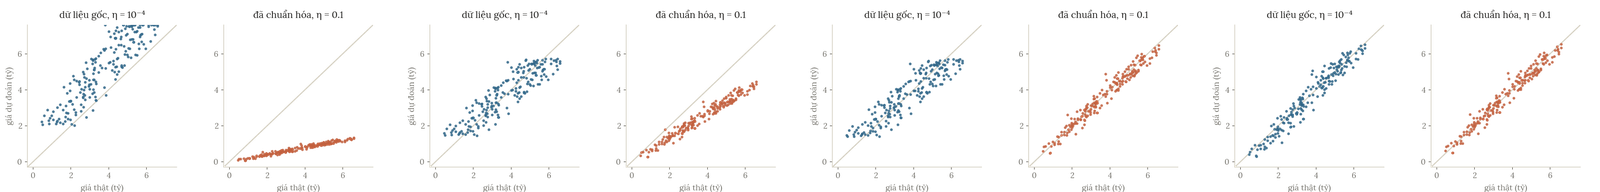

Dữ liệu đã bị biến đổi, vậy mô hình học được có còn là mô hình định giá nhà ban đầu không? Vẫn là nó, chỉ khác cách viết. Mô hình học trên $\mathbf{z}$ nên trọng số cũng theo thang đo của $\mathbf{z}$. Muốn đọc lại bằng m² và km như ban đầu, ta thay $z_j = (x_j - \mu_j)/\sigma_j$ vào:

$$\hat y = \sum_j w^{(z)}_j \,\frac{x_j - \mu_j}{\sigma_j} + b^{(z)} = \sum_j \frac{w^{(z)}_j}{\sigma_j}\, x_j + \Big(b^{(z)} - \sum_j \frac{w^{(z)}_j \mu_j}{\sigma_j}\Big),$$

nên trọng số và bias theo đơn vị gốc là

$$w_j = \frac{w^{(z)}_j}{\sigma_j}, \qquad b = b^{(z)} - \sum_j \frac{w^{(z)}_j \mu_j}{\sigma_j}.$$

In [ ]:
theta_s, _ = gd(Xs, y, 0.1, 200)
w_gd = theta_s[:2] / sigma
b_gd = theta_s[2] - np.sum(theta_s[:2] * mu / sigma)
print(w_gd.round(4), round(b_gd, 4))

[ 0.0499 -0.1453] 0.9809


Khớp với nghiệm đóng đến chữ số thứ tư.

**Hỏi nhanh.** Chuẩn hóa feature rồi học lại cho tới khi MSE chạm đáy. So với mô hình học trên dữ liệu gốc, cái gì thay đổi?

- A. Dự đoán chính xác hơn, vì thang đo tốt hơn
- B. Trọng số giữ nguyên, chỉ bias đổi theo trung bình
- C. Dự đoán y hệt, chỉ cách viết trọng số và tốc độ của gradient descent đổi
- D. `LinearRegression` của scikit-learn cũng hội tụ nhanh hơn

<details><summary>Đáp án</summary>

C. Dự đoán y hệt, chỉ cách viết trọng số và tốc độ của gradient descent đổi

Chuẩn hóa là một phép đổi biến tuyến tính, nên tập các mô hình học được vẫn như cũ, và đáy của MSE vẫn cho cùng dự đoán. Công thức đổi ngược ở trên cho lại đúng trọng số gốc. Thứ thay đổi là hình dạng thung lũng, nên gradient descent tới đáy nhanh hơn hàng nghìn lần. `LinearRegression` giải trực tiếp, không lặp, nên chẳng có gì để “hội tụ nhanh hơn”.

</details>

> **Chuẩn hóa bằng số liệu của tập train**
>
> $\mu$ và $\sigma$ phải tính trên tập train, rồi dùng đúng hai con số đó để biến đổi validation và test. Tính lại trên test là để lọt thông tin của test vào mô hình (bài 1.3). Cột hằng số có $\sigma = 0$; bỏ cột đó trước khi chia. Với ảnh, giá trị điểm ảnh thường được chia cho 255 để về $[0, 1]$, và lúc dự đoán phải biến đổi đúng như lúc huấn luyện. Nhân một đặc trưng với hằng số $c$ thì least squares chỉ chia trọng số của nó cho $c$, dự đoán không đổi; với regularization ở bài 2.2 thì không còn đúng hẳn, vì phạt theo độ lớn trọng số.

## Dùng scikit-learn

Trong thực tế, nhất là trong phòng thi, nên dùng thư viện cho nhanh và chắc. Quy trình chuẩn là chia dữ liệu, học trên tập train, chấm trên tập test:

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0)
model = LinearRegression().fit(X_tr, y_tr)
print(model.coef_.round(4), round(model.intercept_, 4))
print(model.score(X_tr, y_tr), model.score(X_te, y_te))

[ 0.0496 -0.1437] 0.9966
0.9604123189943734 0.9689505848749018


`model.score` trả về $R^2$, đúng đại lượng ta định nghĩa ở phần hàm mất mát. Điểm trên train ($0.960$) và trên test ($0.969$) sát nhau là dấu hiệu tốt: chưa thấy khoảng cách train/test đáng kể ở lần chia này; chưa đủ để bảo đảm không overfit trên mọi tập dữ liệu.

Điểm test cao hơn train một chút không có gì đặc biệt: tập test chỉ có 40 căn, nên chênh lệch cỡ này phụ thuộc cách chia, đổi `random_state` thì con số cũng đổi. Hệ số cũng hơi khác lúc nãy, vì lần này mô hình chỉ được học trên 160 căn.

`LinearRegression` giải least squares trực tiếp bằng phân tích ma trận, giống `lstsq`, chứ không dùng gradient descent, nên nó không cần chuẩn hóa mới hội tụ.

Còn code tự viết thì sao? Cho cả ba cách chạy trên cùng dữ liệu rồi so:

In [ ]:
full = LinearRegression().fit(X, y)
print(np.allclose(full.coef_, w_cf), np.allclose(full.intercept_, b_cf))
print(np.allclose(w_gd, w_cf), np.allclose(b_gd, b_cf))

True True
True True


Cả bốn kết quả đều `True`. Lưu ý dùng `np.allclose` chứ không dùng `==`: hai cách tính cùng đúng vẫn có thể lệch nhau ở chữ số thứ mười lăm. Tự cài lại rồi đối chiếu với thư viện giúp hiểu thư viện đang làm gì; khi cần kết quả thì dùng thư viện.

Sau khi huấn luyện, trọng số nằm ở `model.coef_`, bias ở `model.intercept_`: scikit-learn đặt mọi thứ học được vào thuộc tính có dấu gạch dưới ở cuối. Cần đọc chúng đúng cách. Có ba điểm cần nhớ.

Thứ nhất, hệ số phụ thuộc đơn vị. Hệ số của diện tích ($0.05$) nhỏ hơn hệ số của khoảng cách ($-0.15$) về độ lớn, nhưng không có nghĩa là diện tích ít quan trọng hơn, vì một m² và một km không so sánh trực tiếp được. Muốn so thì so hệ số sau khi chuẩn hóa.

Thứ hai, hệ số đo mối liên hệ **khi giữ các biến khác cố định**, không phải quan hệ nhân quả. Doanh số kem và số vụ đuối nước cùng tăng vào mùa hè; mô hình sẽ cho hệ số dương, nhưng cấm bán kem không làm giảm số vụ đuối nước.

Thứ ba, luôn vẽ phần dư: trục ngang là dự đoán, trục dọc là phần dư. Mô hình ổn thì các điểm rải đều quanh đường 0, không theo hình thù gì. Phần dư uốn cong là mô hình đang thiếu đặc trưng phi tuyến; phần dư loe dần ra là nên biến đổi $y$, chẳng hạn lấy log.



**Hỏi nhanh.** Linear regression cho hệ số dương giữa số kem bán ra và số vụ đuối nước mỗi tuần. Chỉ từ kết quả này, ta kết luận được gì?

- A. Giảm bán kem sẽ giảm số vụ đuối nước đúng theo hệ số
- B. Ăn kem làm tăng nguy cơ đuối nước khi bơi
- C. Nhiệt độ chắc chắn là nguyên nhân duy nhất của cả hai
- D. Hai đại lượng cùng tăng, còn tác động của kem thì chưa biết

<details><summary>Đáp án</summary>

D. Hai đại lượng cùng tăng, còn tác động của kem thì chưa biết

Hệ số học từ dữ liệu quan sát chỉ cho biết hai đại lượng đi cùng nhau. Nó chưa nói được chuyện gì sẽ xảy ra nếu ta can thiệp vào việc bán kem. Nhiệt độ là nghi phạm hợp lý cho cả hai, nhưng cũng mới chỉ là giả thuyết.

</details>

## Bẫy cài đặt

Các lỗi dưới đây rất hay gặp.

**Broadcasting âm thầm.** Lỗi nguy hiểm nhất, vì NumPy không báo gì:

In [ ]:
y_col = y.reshape(-1, 1)               # (200, 1), ví dụ khi đọc bằng df[["price"]]
y_hat = predict(X, w_cf, b_cf)         # (200,)
print((y_hat - y_col).shape)
print(mse(y_hat, y), mse(y_hat, y_col))

(200, 200)
0.0880761518040597 4.594878280120055


Trừ mảng `(200,)` cho mảng `(200, 1)`, NumPy tự kéo cả hai thành `(200, 200)`: mỗi dự đoán bị trừ cho cả 200 giá trị thật. Code vẫn chạy, loss ra một con số trông hợp lý nhưng vô nghĩa. Cách phòng: đọc nhãn bằng `df["price"]` thay vì `df[["price"]]`, gọi `.ravel()` khi nghi ngờ, và đặt `assert y_hat.shape == y.shape` ngay đầu hàm loss.

**Bias hai lần, hoặc không có bias.** Đã thêm cột 1 vào `X` rồi lại cộng thêm `b` riêng thì hai tham số cùng làm một việc, nghiệm đóng suy biến. Ngược lại, quên cả hai thì đường thẳng bị ép đi qua gốc tọa độ. `LinearRegression` mặc định tự lo phần bias (`fit_intercept=True`), nên đừng đưa cho nó ma trận đã có cột 1.

**Mảng số nguyên.** `w = np.array([0, 0])` là mảng kiểu `int`, nên dòng `w -= lr * g` sẽ báo lỗi ép kiểu. Khởi tạo bằng `np.zeros(d)`, hoặc ghi rõ `dtype=float`.

**$\frac{1}{n}$ hay $\frac{1}{2n}$.** Nhiều sách thêm $\frac12$ vào loss cho đạo hàm gọn, khi đó gradient nhỏ đi một nửa. Không ai sai cả, nhưng chép learning rate từ sách này sang code viết theo sách kia thì lệch hai lần, và lỗi này rất khó phát hiện.

**Hỏi nhanh.** `y_hat` có shape `(5, 1)`, `y` có shape `(5,)`. `y_hat - y` cho ra gì?

- A. Báo lỗi, vì hai shape khác nhau
- B. Mảng shape `(5,)`
- C. Mảng shape `(5, 1)`
- D. Mảng shape `(5, 5)`

<details><summary>Đáp án</summary>

D. Mảng shape `(5, 5)`

NumPy coi `(5,)` như `(1, 5)`, rồi ghép với `(5, 1)`: chiều nào dài 1 thì được kéo dãn cho khớp chiều kia. Kết quả có shape `(5, 5)`, và không có lỗi nào được báo.

</details>

## Tuyến tính theo tham số

Quan hệ trong thực tế thường không thẳng: giá nhà không tăng đều theo diện tích mãi. Nhưng chữ “tuyến tính” trong tên mô hình là tuyến tính theo $\mathbf{w}$, không phải theo $\mathbf{x}$. Đặc trưng có thể biến đổi tùy ý: thêm $x^2, x^3$ là polynomial regression (hồi quy đa thức), thêm $\log x$, $\sqrt{x}$ hay tích $x_1 x_2$ cũng vậy, và tất cả vẫn giải bằng đúng code của bài này. Thêm quá nhiều thì mô hình bắt đầu học thuộc cả nhiễu, đúng chuyện overfitting ở bài 1.2. Dữ liệu hình chữ U khớp kém bằng đường thẳng thì thêm cột $x^2$ là đủ. Với least squares có bias, thêm đặc trưng không bao giờ làm lỗi train tăng, vì mô hình luôn có thể đặt trọng số mới bằng 0; lỗi validation thì có thể tăng.

Một ứng dụng cho lập trình thi đấu: đoán độ phức tạp của chương trình trước khi nộp. Nếu thời gian chạy $t \approx C n^k$ thì lấy log hai vế:

$$\log t = k \log n + \log C.$$

Đó là một đường thẳng theo $\log n$, và hệ số góc chính là số mũ $k$. Đo thời gian chạy với vài giá trị $n$, rồi hồi quy. `np.polyfit(x, y, 1)` chính là linear regression với một đặc trưng, trả về hệ số góc và hệ số tự do:

In [ ]:
ns = np.array([1e3, 2e3, 5e3, 1e4, 2e4, 5e4])
t = np.array([0.0011, 0.0042, 0.026, 0.098, 0.41, 2.47])    # giây, đo trên máy nhà
k, c = np.polyfit(np.log(ns), np.log(t), 1)                  # least squares bậc 1
print(round(k, 2))
print(np.exp(c) * 2e5 ** k)                                  # dự đoán cho n = 2·10⁵

1.98
37.89981222044977




Hệ số góc xấp xỉ 2 gợi ý thời gian trong miền đã đo tăng gần theo $n^2$; số đo hữu hạn không chứng minh độ phức tạp Big-O. Ngoại suy cho $n = 2 \cdot 10^5$ cho ước lượng khoảng 38 giây, so với giới hạn giả định 1 giây. Cần kiểm thêm thuật toán, miền đầu vào và máy chạy trước khi coi ngoại suy là đáng tin.

**Hỏi nhanh.** Sau khi tạo thêm feature, mô hình nào **không** giải được bằng code linear regression của bài này?

- A. $\hat y = w_1 x + w_2 x^2 + b$
- B. $\hat y = w_1 \log x + b$
- C. $\hat y = w_1 x_1 x_2 + w_2 x_1 + b$
- D. $\hat y = e^{w x} + b$

<details><summary>Đáp án</summary>

D. $\hat y = e^{w x} + b$

Ba mô hình đầu tuyến tính theo các tham số $w$. Chỉ cần tạo thêm cột $x^2$, $\log x$ hay $x_1 x_2$ là giải như thường. Ở mô hình cuối, $w$ nằm trong hàm mũ, nên mô hình không còn tuyến tính theo tham số.

</details>

## Khi đi thi

- **Luôn có baseline.** Gặp bài hồi quy, việc đầu tiên là chạy một `LinearRegression`. Mười dòng code, vài giây, cho một mốc mà mọi mô hình phức tạp hơn phải vượt qua. Không vượt được thì mô hình phức tạp đang có vấn đề.
- **Loss nổ thì nghĩ đến thang đo và learning rate.** Chuẩn hóa trước, chỉnh $\eta$ sau.
- **Target lệch thì lấy log.** Giá nhà, lượt xem, doanh thu thường lệch phải. Học trên $\log(1+y)$ rồi đổi ngược bằng $e^{\hat z} - 1$; nếu metric là RMSLE (sai số tính trên log của giá trị) thì loss trên thang log là một lựa chọn phù hợp để thử; kiểm lại giá trị không âm, phép đổi ngược và metric chính xác của đề.
- **Cẩn thận khi ngoại suy.** Mô hình tuyến tính kéo xu hướng ra ngoài vùng dữ liệu, mô hình cây thì không (bài 2.5). Khi test nằm ở tương lai và dữ liệu đang có xu hướng tăng, khác biệt này có thể quyết định thắng thua.
- **Tự viết thì tự kiểm.** Khi phải cài một thứ thư viện không có sẵn, kiểm shape và kiểm gradient trên dữ liệu nhỏ rồi mới chạy thật. Mười phút kiểm tra rẻ hơn nhiều so với hai tiếng huấn luyện một mô hình sai.

## Tóm tắt

- Linear regression dự đoán $\hat y = \mathbf{w}^\top\mathbf{x} + b$ và học bằng cách cực tiểu MSE. Mô hình đoán trung bình có MSE bằng $\operatorname{Var}(y)$; $R^2$ cho biết ta thắng mốc đó bao nhiêu.
- Nghiệm đóng: thêm cột 1 rồi giải hệ phương trình chuẩn bằng `solve`. Về hình học, đó là phép chiếu vuông góc của $\mathbf{y}$.
- Gradient descent đi từng bước ngược gradient và hội tụ khi $\eta < 2/\lambda_{\max}$. Số điều kiện quyết định nhanh hay chậm, và chuẩn hóa đặc trưng kéo nó về gần 1.
- Trong thực tế, dùng scikit-learn với train/test; đọc hệ số như mối liên hệ chứ không như nhân quả; giữ vector ở shape `(n,)`.
- “Tuyến tính” là theo tham số, nên đặc trưng biến đổi tùy ý, kể cả $\log n$ để đoán độ phức tạp.

## Kiểm tra cuối bài

Mười câu dưới đây bao quát cả bài. Làm hết rồi xem điểm; câu nào sai thì đọc lại mục tương ứng.

**Câu 1.** Hệ phương trình chuẩn của một bộ dữ liệu có số điều kiện cỡ $10^{10}$. Vì sao điều này đáng lo khi giải bằng máy?

- A. Ma trận chắc chắn suy biến, nên hệ vô nghiệm
- B. Định thức cỡ $10^{10}$ nên phép tính bị tràn số
- C. Ma trận có quá nhiều phần tử khác 0 nên chạy chậm
- D. Sai số nhỏ ở dữ liệu có thể thành sai số lớn ở nghiệm

<details><summary>Đáp án</summary>

D. Sai số nhỏ ở dữ liệu có thể thành sai số lớn ở nghiệm

Số điều kiện $\kappa$ cho biết sai lệch tương đối nhỏ ở đầu vào, kể cả sai số làm tròn, có thể bị phóng to tới cỡ $\kappa$ lần ở nghiệm. Ma trận vẫn có thể khả nghịch, còn định thức hay số phần tử khác 0 là chuyện khác. Đây cũng là lý do gradient descent bò chậm khi $\kappa \approx 10^5$ trong bài, và chuẩn hóa chữa được cả hai.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 35](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=16)

</details>

**Câu 2.** Trên cùng một tập, MSE của mô hình bằng 1 và variance của $y$ bằng 4, cả hai đều chia cho số mẫu $n$. $y$ không phải hằng số. $R^2$ bằng bao nhiêu?

- A. 3
- B. $-3$
- C. 0.75
- D. 0.25

<details><summary>Đáp án</summary>

C. 0.75

$R^2 = 1 - \text{MSE}/\operatorname{Var}(y) = 1 - 1/4 = 0.75$. Công thức này chỉ đúng khi MSE và variance cùng chia cho $n$. Ra 0.25 là quên lấy 1 trừ đi.

</details>

**Câu 3.** Với $L(\theta) = N^{-1}\sum_{n=0}^{N-1}(y_n - \theta^\top x_n)^2$, gradient theo $\theta$ là gì?

- A. $\frac{2}{N}\sum(\theta^\top x_n - y_n)$
- B. $\frac{2}{N}\sum(\theta^\top x_n - y_n)x_n$
- C. $\frac{2}{N}\sum(y_n - \theta^\top x_n)x_n$
- D. $\frac{1}{N}\sum(\theta^\top x_n - y_n)x_n$

<details><summary>Đáp án</summary>

B. $\frac{2}{N}\sum(\theta^\top x_n - y_n)x_n$

Đạo hàm của bình phương phần dư cho hệ số 2, dấu theo hiệu dự đoán trừ target, và nhân với vector $x_n$. Phương án thứ nhất quên nhân $x_n$, phương án thứ ba sai dấu, phương án cuối thiếu hệ số 2.
Đề thi: [USA-NA-AIO 2026 · Vòng 1 · Part 4.2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=8)

</details>

**Câu 4.** Cho $J(w) = (w - 3)^2$, xuất phát từ $w = 0$ với $\eta = 0.25$. Sau một bước gradient descent, $w$ bằng bao nhiêu?

- A. $1.5$
- B. $0.75$
- C. $6$
- D. $-1.5$

<details><summary>Đáp án</summary>

A. $1.5$

Tại $w = 0$, $J'(w) = 2(w - 3) = -6$. Vậy $w \leftarrow 0 - 0.25 \cdot (-6) = 1.5$.

</details>

**Câu 5.** Vẫn với $J(w) = (w - 3)^2$. Learning rate nào làm gradient descent phân kỳ?

- A. $0.1$
- B. $0.5$
- C. $0.9$
- D. $1.2$

<details><summary>Đáp án</summary>

D. $1.2$

Đạo hàm bậc hai bằng 2, nên $\lambda_{\max} = 2$ và cần $\eta < 2/2 = 1$. Với $\eta = 0.9$, mỗi bước sai số nhân với $1 - 0.9 \cdot 2 = -0.8$, vẫn co lại dù đổi dấu. Với $\eta = 1.2$ thì nhân với $-1.4$, nên sai số lớn dần.

</details>

**Câu 6.** Công thức nghiệm $\boldsymbol\theta^\ast = (\tilde X^\top\tilde X)^{-1}\tilde X^\top\mathbf y$ dùng được khi nào?

- A. Luôn luôn, với mọi ma trận dữ liệu
- B. Khi $\tilde X$ vuông, tức số mẫu bằng số cột
- C. Khi các cột của $\tilde X$ độc lập tuyến tính
- D. Khi $\tilde X$ đối xứng qua đường chéo

<details><summary>Đáp án</summary>

C. Khi các cột của $\tilde X$ độc lập tuyến tính

Cần $\tilde X^\top\tilde X$ khả nghịch, tức là các cột của $\tilde X$ độc lập tuyến tính. Cột “diện tích theo dm²” ở trên phá đúng điều kiện này. Ma trận dữ liệu gần như không bao giờ vuông hay đối xứng, vì thường có nhiều mẫu hơn feature.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 34](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=16)

</details>

**Câu 7.** Một feature có độ lệch chuẩn $\sigma = 10$. Học trên dữ liệu đã chuẩn hóa, nó nhận trọng số $w^{(z)} = 0.5$. Theo đơn vị gốc, trọng số của nó là bao nhiêu?

- A. $0.05$
- B. $5$
- C. $0.5$
- D. $25$

<details><summary>Đáp án</summary>

A. $0.05$

$w = w^{(z)}/\sigma = 0.5/10 = 0.05$, vì tăng $x$ một đơn vị gốc thì $z$ chỉ tăng $1/10$.

</details>

**Câu 8.** Ta đọc `y = df[["price"]].to_numpy()`, được shape `(100, 1)`, còn `y_hat` có shape `(100,)`. Dòng nào tính đúng MSE?

- A. `np.mean((y_hat - y.ravel()) ** 2)`
- B. `np.mean((y_hat - y) ** 2)`
- C. `np.mean((y_hat - y.T) ** 2)`
- D. `np.mean(y_hat - y.ravel()) ** 2`

<details><summary>Đáp án</summary>

A. `np.mean((y_hat - y.ravel()) ** 2)`

`y.ravel()` đưa `y` về `(100,)`, để phần dư ghép đúng từng cặp mẫu. Trừ thẳng `y` hay `y.T` đều bị broadcasting thành ma trận 100 × 100. Phương án cuối là bình phương của trung bình phần dư, khác với trung bình của bình phương.

</details>

**Câu 9.** Gradient do hàm `grad` tự viết lệch tương đối $0.5$ so với gradient tính bằng sai phân. Ta nên làm gì?

- A. Coi như đúng, vì sai phân chỉ là xấp xỉ
- B. Tìm lỗi trong `grad` trước khi chạy tiếp
- C. Giảm $h$ xuống $10^{-12}$ rồi kiểm lại
- D. Tăng learning rate để bù phần gradient thiếu

<details><summary>Đáp án</summary>

B. Tìm lỗi trong `grad` trước khi chạy tiếp

Lỗi hay gặp nhất là sai dấu, thiếu hệ số, hoặc nhân ma trận sai thứ tự. Trong bài, bản đúng chỉ lệch cỡ $10^{-13}$. Lệch tới 0.5 thì gần như chắc chắn code sai. Giảm $h$ xuống $10^{-12}$ không giúp gì, còn làm sai số làm tròn lớn thêm.

</details>

**Câu 10.** Mô hình định giá nhà có trọng số của diện tích là $0.05$ tỷ đồng mỗi m². Hai căn hộ giống nhau ở mọi feature khác, chỉ chênh nhau 10 m². Giá dự đoán chênh nhau bao nhiêu?

- A. $0.05$ tỷ
- B. $0.5$ tỷ
- C. $5$ tỷ
- D. Chưa biết, vì còn phụ thuộc khoảng cách

<details><summary>Đáp án</summary>

B. $0.5$ tỷ

Khi các feature khác giữ nguyên, dự đoán chênh đúng $w \cdot \Delta x = 0.05 \cdot 10 = 0.5$ tỷ. Hai căn có cùng khoảng cách, nên khoảng cách không ảnh hưởng tới phần chênh.

</details>

## Đọc thêm

- James, Witten, Hastie, Tibshirani — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chương 3. Linear regression từ góc nhìn thống kê: độ tin cậy của hệ số, tương tác giữa các đặc trưng, các vấn đề thường gặp. Sách miễn phí, có bản dùng Python.
- Géron — *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*, chương 4 “Training Models”. Nghiệm đóng, các biến thể của gradient descent, polynomial regression và learning curve, viết rất thực hành.
- Zhang và cộng sự — [*Dive into Deep Learning*](https://d2l.ai/chapter_linear-regression/index.html), chương 3. Linear regression được trình bày như một mạng neural một lớp, cài từ đầu rồi bằng PyTorch; cầu nối sang Phase 3.
- Andrew Ng — [*CS229 Lecture Notes*](https://cs229.stanford.edu/main_notes.pdf), chương 1. Least squares, phương trình chuẩn, và lý do xác suất đứng sau việc dùng MSE.
- Boyd, Vandenberghe — [*Introduction to Applied Linear Algebra*](https://web.stanford.edu/~boyd/vmls/), chương 12–13. Least squares bằng đại số tuyến tính với nhiều ví dụ ứng dụng; dành cho ai muốn hiểu sâu phần nghiệm đóng. Sách miễn phí.
- 3Blue1Brown — [*Essence of Linear Algebra*](https://www.3blue1brown.com/topics/linear-algebra). Loạt video trực quan về vector, ma trận, phép chiếu và trị riêng.
- Gabriel Goh — [*Why Momentum Really Works*](https://distill.pub/2017/momentum/), Distill (2017). Phân tích gradient descent trên hàm bậc hai qua trị riêng và số điều kiện, có hình tương tác; đọc sau mục chọn learning rate.
- Stanford CS231n — [*Gradient checks*](https://cs231n.github.io/neural-networks-3/#gradcheck). Các lưu ý khi kiểm gradient bằng sai phân trong thực tế.
- Tài liệu chính thức: [NumPy — Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html), [scikit-learn — Linear Models](https://scikit-learn.org/stable/modules/linear_model.html).